# Handwritten Math Recognition: ViT

Pipeline: contour segmentation → Vision Transformer symbol classifier → layout-aware parser → SymPy solver.

**Quick start:** run all cells. With `TRAIN = False` (the default), the notebook loads `weights/vit.pth` and runs on the images in `examples/`; no dataset needed.

**Retrain:** download the data with `python scripts/download_data.py`, set `TRAIN = True`, and run all cells (4 epochs).

## Setup

In [1]:
import os
import re
import random

import cv2
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from PIL import Image
from tqdm.auto import tqdm
from sympy.parsing.latex import parse_latex

# ---- Configuration -------------------------------------------------------
TRAIN = False                  # True: retrain from DATA_PATH. False: load WEIGHTS_PATH.
DATA_PATH = 'data'             # one folder per class (see scripts/download_data.py)
WEIGHTS_PATH = 'weights/vit.pth'
EXAMPLES_DIR = 'examples'
OUTPUT_DIR = 'outputs'         # boxes.png (detected symbols) is written here
SHOW_STEPS = True              # plot the detected boxes and each symbol patch

ALLOWED_CLASSES = ['forward_slash', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
                   '+', '-', '(', ')', 'd', 'X', 'int', 'lt', 'leq', 'gt', 'geq', '=', 'neq']
LABELS = sorted(ALLOWED_CLASSES)   # same order ImageFolder assigns
NUM_CLASSES = len(LABELS)
IMG_H, IMG_W = 45, 45
BATCH_SZ = 32
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

if torch.cuda.is_available():
    compute_device = torch.device('cuda')
elif torch.backends.mps.is_available():
    compute_device = torch.device('mps')
else:
    compute_device = torch.device('cpu')
print('Device:', compute_device)
print('Labels:', LABELS)

Device: mps
Labels: ['(', ')', '+', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '=', 'X', 'd', 'forward_slash', 'geq', 'gt', 'int', 'leq', 'lt', 'neq']


In [2]:
# Utility Functions for Image Processing
############################################

def apply_binarization(img):
    if isinstance(img, Image.Image):
        img = np.array(img)
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    # same parameters as training
    thresh = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                   cv2.THRESH_BINARY, 15, 3)
    return cv2.bitwise_not(thresh)

class AdaptiveBinarization:
    def __call__(self, img):
        arr = np.array(img)
        bin_img = apply_binarization(arr)
        return torch.tensor(bin_img, dtype=torch.float32).unsqueeze(0) / 255.0

## Data (training only)

In [3]:
class FilteredRAMCachedDataset(torch.utils.data.Dataset):
    def __init__(self, root, allowed_classes, transform=None):
        self.dataset = ImageFolder(root)
        self.transform = transform

        # Filter classes
        self.class_to_idx = {
            cls: i for i, cls in enumerate(cls for cls in self.dataset.classes if cls in allowed_classes)
        }
        self.classes = list(self.class_to_idx.keys())

        # Filter and cache images
        self.cached_images = []
        for path, label in tqdm(self.dataset.samples, desc='Caching images'):
            class_name = self.dataset.classes[label]
            if class_name in self.class_to_idx:
                new_label = self.class_to_idx[class_name]
                image = Image.open(path).convert("RGB")
                self.cached_images.append((image, new_label))

    def __len__(self):
        return len(self.cached_images)

    def __getitem__(self, idx):
        image, label = self.cached_images[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

In [4]:
# Data and Transform Setup (only needed for training)
############################################

data_transforms = T.Compose([
    T.Grayscale(),
    T.Resize((IMG_H, IMG_W)),
    AdaptiveBinarization()
])

if TRAIN:
    dataset = FilteredRAMCachedDataset(DATA_PATH, ALLOWED_CLASSES, transform=data_transforms)
    assert dataset.classes == LABELS, f"Missing classes in {DATA_PATH}: {set(LABELS) - set(dataset.classes)}"

    n = len(dataset)
    n_train = int(0.95 * n)
    n_val = n - n_train
    train_ds, val_ds = random_split(dataset, [n_train, n_val],
                                    generator=torch.Generator().manual_seed(SEED))

    pin = compute_device.type == 'cuda'
    train_loader = DataLoader(train_ds, batch_size=BATCH_SZ, shuffle=True, num_workers=0, pin_memory=pin)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SZ, shuffle=False, num_workers=0, pin_memory=pin)
    print(f"Train samples: {len(train_ds)}, Val samples: {len(val_ds)}")
else:
    print("TRAIN is False: skipping dataset loading.")

TRAIN is False: skipping dataset loading.


## Model

In [5]:
# Vision Transformer Model
############################################

class PatchEmbedding(nn.Module):
    def __init__(self, img_size=45, patch_size=5, in_chans=1, embed_dim=64):
        super().__init__()
        assert img_size % patch_size == 0, "Image size must be divisible by patch size"
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))

    def forward(self, x):
        B = x.size(0)
        x = self.proj(x)                  # [B, embed_dim, H', W']
        x = x.flatten(2).transpose(1, 2)  # [B, num_patches, embed_dim]
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        return x + self.pos_embed


class ViTClassifier(nn.Module):
    def __init__(self, num_classes, img_size=45, patch_size=5,
                 embed_dim=64, depth=6, num_heads=8, mlp_dim=128, dropout=0.1):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, 1, embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=mlp_dim,
            dropout=dropout, activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth,
                                                 enable_nested_tensor=False)
        self.mlp_head = nn.Sequential(nn.LayerNorm(embed_dim), nn.Linear(embed_dim, num_classes))

    def forward(self, x):
        x = self.patch_embed(x)          # [B, P+1, embed_dim]
        x = self.transformer(x)
        return self.mlp_head(x[:, 0])    # classify from the CLS token

In [6]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=4):
    for epoch in range(1, epochs+1):
        # ——— Training ———
        model.train()
        running_loss = correct = total = 0
        for images, targets in tqdm(train_loader, desc=f"Epoch {epoch}/{epochs} [Train]"):
            images, targets = images.to(compute_device), targets.to(compute_device)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds       = outputs.argmax(dim=1)
            correct    += (preds == targets).sum().item()
            total      += targets.size(0)

        train_loss = running_loss / total
        train_acc  = correct / total * 100

        # ——— Validation ———
        model.eval()
        val_loss = val_correct = val_total = 0
        with torch.no_grad():
            for images, targets in tqdm(val_loader, desc=f"Epoch {epoch}/{epochs} [Val]  "):
                images, targets = images.to(compute_device), targets.to(compute_device)
                outputs = model(images)
                loss    = criterion(outputs, targets)

                val_loss    += loss.item() * images.size(0)
                preds        = outputs.argmax(dim=1)
                val_correct += (preds == targets).sum().item()
                val_total   += targets.size(0)

        val_loss = val_loss / val_total
        val_acc  = val_correct / val_total * 100

        print(
            f"Epoch {epoch}: "
            f"Train Loss = {train_loss:.4f}, Train Acc = {train_acc:.2f}% | "
            f"Val Loss = {val_loss:.4f}, Val Acc = {val_acc:.2f}%"
        )

    return model

In [7]:
model = ViTClassifier(num_classes=NUM_CLASSES).to(compute_device)

if TRAIN:
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    model = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=4)
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    torch.save(model.state_dict(), WEIGHTS_PATH)
    print("Training complete. Saved", WEIGHTS_PATH)
else:
    model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=compute_device, weights_only=True))
    print("Loaded", WEIGHTS_PATH)
model.eval();

Loaded weights/vit.pth


In [8]:
from sklearn.metrics import classification_report

if TRAIN:
    all_preds, all_labels = [], []
    model.eval()
    with torch.no_grad():
        for imgs, lbls in val_loader:
            out = model(imgs.to(compute_device))
            all_preds.extend(out.argmax(1).cpu().numpy())
            all_labels.extend(lbls.numpy())

    print(classification_report(all_labels, all_preds, target_names=LABELS, digits=4))
    report = classification_report(all_labels, all_preds, target_names=LABELS,
                                   digits=4, output_dict=True)
    cell_text = [[f"{report[c]['precision']:.4f}", f"{report[c]['recall']:.4f}",
                  f"{report[c]['f1-score']:.4f}", f"{int(report[c]['support'])}"] for c in LABELS]
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.axis('off')
    tbl = ax.table(cellText=cell_text, rowLabels=LABELS,
                   colLabels=['Precision', 'Recall', 'F1-score', 'Support'],
                   cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.5)
    plt.title('Per-Class Classification Report (ViT)')
    plt.show()
else:
    print("TRAIN is False: skipping validation report (needs the dataset).")

TRAIN is False: skipping validation report (needs the dataset).


## Segmentation, recognition and parsing

In [9]:
# Segmentation
############################################
# Every threshold here is relative to the image itself (its measured stroke width
# and typical symbol height), so the same code works on small scans and large photos.

def odd(n):
    n = int(n)
    return n + 1 - n % 2

def binarize(gray, weak=0.5):
    """Ink mask (white ink on black) that tolerates uneven lighting and faint strokes.

    1. Divide by a heavy blur (sized to the image) to flatten shadows and paper tint.
    2. Otsu's threshold picks the confident ink.
    3. Hysteresis: fainter pixels (up to `weak` of the way from the Otsu level to the
       background) are kept only where they connect to confident ink.
    """
    k = odd(max(31, min(gray.shape) // 6))
    norm = cv2.divide(gray, cv2.GaussianBlur(gray, (k, k), 0), scale=255)
    t, strong = cv2.threshold(norm, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    weak_mask = (norm < t + weak * (255 - t)).astype(np.uint8)
    n, lab = cv2.connectedComponents(weak_mask, connectivity=8)
    keep = np.zeros(n, bool)
    keep[np.unique(lab[strong > 0])] = True
    keep[0] = False
    return keep[lab].astype(np.uint8) * 255

def stroke_width(mask):
    """Typical pen width in pixels, from the distance transform of the ink."""
    dt = cv2.distanceTransform(mask, cv2.DIST_L2, 3)
    vals = dt[dt > 0]
    return max(1.0, 2 * float(np.percentile(vals, 90))) if vals.size else 1.0

def thin(img):
    """Zhang-Suen thinning of a 0/1 image to 1-pixel strokes.
    The training symbols have 1-pixel strokes, while pen strokes in photos are much thicker."""
    x = np.pad(img.astype(np.uint8), 1)
    changed = True
    while changed:
        changed = False
        for step in (0, 1):
            P = [x[:-2, 1:-1], x[:-2, 2:], x[1:-1, 2:], x[2:, 2:],
                 x[2:, 1:-1], x[2:, :-2], x[1:-1, :-2], x[:-2, :-2]]
            B = sum(p.astype(int) for p in P)
            A = sum(((P[i] == 0) & (P[(i + 1) % 8] == 1)).astype(int) for i in range(8))
            if step == 0:
                m = (P[0] * P[2] * P[4] == 0) & (P[2] * P[4] * P[6] == 0)
            else:
                m = (P[0] * P[2] * P[6] == 0) & (P[0] * P[4] * P[6] == 0)
            remove = (x[1:-1, 1:-1] == 1) & (B >= 2) & (B <= 6) & (A == 1) & m
            if remove.any():
                x[1:-1, 1:-1][remove] = 0
                changed = True
    return x[1:-1, 1:-1]

def to_patch(mask, size=45):
    """Crop -> aspect-preserving resize centred in size x size -> 1-pixel strokes."""
    h, w = mask.shape
    s = size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    resized = cv2.resize(mask, (nw, nh), interpolation=cv2.INTER_AREA)
    out = np.zeros((size, size), np.uint8)
    y0, x0 = (size - nh) // 2, (size - nw) // 2
    out[y0:y0 + nh, x0:x0 + nw] = resized
    return thin(out > 64) * 255

def _union(a, b):
    (ax, ay, aw, ah), (bx, by, bw, bh) = a['box'], b['box']
    x1, y1 = min(ax, bx), min(ay, by)
    x2, y2 = max(ax + aw, bx + bw), max(ay + ah, by + bh)
    return dict(ids=a['ids'] + b['ids'], box=[x1, y1, x2 - x1, y2 - y1], area=a['area'] + b['area'])

def _should_merge(a, b, sw, H):
    (ax, ay, aw, ah), (bx, by, bw, bh) = a['box'], b['box']
    ox = min(ax + aw, bx + bw) - max(ax, bx)   # horizontal overlap (negative = gap)
    oy = min(ay + ah, by + bh) - max(ay, by)   # vertical overlap
    # Stacked strokes of one symbol (=, <=, >=, !=): pieces of comparable width that
    # overlap horizontally and are either centred over each other or both flat bars.
    # These checks keep a dot or an exponent from being glued onto a neighbour like ')'.
    centre_offset = abs((ax + aw / 2) - (bx + bw / 2))
    both_flat = ah < 0.5 * aw and bh < 0.5 * bw
    if (ox > 0 and ox >= 0.6 * min(aw, bw) and min(aw, bw) >= 0.4 * max(aw, bw)
            and (centre_offset < 0.25 * max(aw, bw) or both_flat)):
        return True
    # A broken-off piece of a stroke: much smaller than its neighbour and within
    # about one stroke width of it.
    small, big = (a, b) if a['area'] < b['area'] else (b, a)
    size = max(small['box'][2:])
    return (small['area'] < 0.25 * big['area'] and 0.25 * H < size < 0.5 * H
            and ox > -1.5 * sw and oy > -1.5 * sw)

def segment(gray):
    """Split an equation image into symbols.

    Returns (boxes, patches, is_dot), sorted left to right. Each patch is a 45x45
    image of just that symbol's ink, in the same style as the training data.
    """
    mask = binarize(gray)
    sw = stroke_width(mask)

    # Bridge gaps up to one stroke width (e.g. where a faint stroke crosses a dark one),
    # but take each symbol's pixels from the unbridged mask.
    k = odd(sw)
    joined = cv2.morphologyEx(mask, cv2.MORPH_CLOSE,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(joined, connectivity=8)
    lab = np.where(mask > 0, lab, 0)

    comps = [dict(ids=[i], box=list(map(int, stats[i, :4])), area=int(stats[i, 4]))
             for i in range(1, n)]
    comps = [c for c in comps if c['area'] >= 0.5 * sw * sw]          # specks
    if not comps:
        return [], [], []
    tall = [c['box'][3] for c in comps if max(c['box'][2:]) > 2 * sw]
    H = float(np.median(tall or [c['box'][3] for c in comps]))        # typical symbol height
    tall_comps = [c for c in comps if max(c['box'][2:]) > 2 * sw] or comps
    line_top = np.median([c['box'][1] for c in tall_comps])
    line_bottom = np.median([c['box'][1] + c['box'][3] for c in tall_comps])

    def keep(c):
        x, y, w, h = c['box']
        if max(w, h) >= 0.05 * H:
            return True
        # tiny, but a solid round dot inside the line of text: a multiplication dot
        solid_round = 0.5 < w / h < 2 and c['area'] > 0.4 * w * h and max(w, h) >= sw
        return solid_round and line_top < y + h / 2 < line_bottom
    comps = [c for c in comps if keep(c)]

    merged = True
    while merged:
        merged = False
        comps.sort(key=lambda c: c['box'][0])
        for i in range(len(comps)):
            for j in range(i + 1, len(comps)):
                if _should_merge(comps[i], comps[j], sw, H):
                    comps[i] = _union(comps[i], comps.pop(j))
                    merged = True
                    break
            if merged:
                break

    boxes, patches, dots = [], [], []
    for c in comps:
        x, y, w, h = c['box']
        ink = np.isin(lab[y:y + h, x:x + w], c['ids']).astype(np.uint8) * 255
        # A dot (multiplication) is small relative to the other symbols, roundish and solid.
        dots.append(max(w, h) < 0.3 * H and 0.5 < w / h < 2 and c['area'] > 0.4 * w * h)
        boxes.append([x, y, w, h])
        patches.append(to_patch(ink))
    return boxes, patches, dots


In [10]:
# Recognition and layout
############################################

def classify_patches(net, patches):
    """Class probabilities for each 45x45 patch, computed in one batch."""
    batch = torch.tensor(np.stack(patches), dtype=torch.float32).unsqueeze(1) / 255.0
    with torch.no_grad():
        return torch.softmax(net(batch.to(compute_device)), 1).cpu().numpy()

def balance_parentheses(symbols, probs, min_prob=0.01):
    """Use the classifier's second choices to fix unmatched brackets.

    '(' and '1' (or ')' and '1') look alike. When a ')' has no matching '(', the symbol
    before it that the model thought most likely to be '(' becomes '(' (and likewise
    for an unclosed '(').
    """
    symbols = list(symbols)
    if probs is None or not len(probs):
        return symbols
    OPEN, CLOSE = LABELS.index('('), LABELS.index(')')
    fixable = lambda j: symbols[j] not in ('(', ')', '*')

    def unmatched():
        opens = []
        for j, s in enumerate(symbols):
            if s == '(':
                opens.append(j)
            elif s == ')':
                if not opens:
                    return 'close', j
                opens.pop()
        return ('open', opens[-1]) if opens else (None, None)

    for _ in range(len(symbols)):
        kind, j = unmatched()
        if kind is None:
            break
        if kind == 'close':
            cands, cls, new = [k for k in range(j) if fixable(k)], OPEN, '('
        else:
            cands, cls, new = [k for k in range(j + 1, len(symbols)) if fixable(k)], CLOSE, ')'
        if not cands:
            break
        best = max(cands, key=lambda k: probs[k][cls])
        if probs[best][cls] < min_prob:
            break
        symbols[best] = new
    return symbols

def show_steps(gray, boxes, patches, symbols):
    overlay = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    t = max(2, gray.shape[1] // 400)
    for x, y, w, h in boxes:
        cv2.rectangle(overlay, (x, y), (x + w, y + h), (0, 0, 255), t)
    cv2.imwrite(os.path.join(OUTPUT_DIR, 'boxes.png'), overlay)
    plt.figure(figsize=(10, 3))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f'{len(boxes)} symbols detected')
    plt.axis('off')
    plt.show()
    fig, axes = plt.subplots(1, len(patches), figsize=(1.2 * len(patches), 1.6), squeeze=False)
    for ax, p, s in zip(axes[0], patches, symbols):
        ax.imshow(p, cmap='gray')
        ax.set_title(s)
        ax.axis('off')
    plt.show()

def recognize_equation(net, gray):
    """Segment and classify. Returns (boxes, symbols) left to right."""
    boxes, patches, dots = segment(gray)
    probs = classify_patches(net, patches) if patches else None
    symbols = []
    for k, is_dot in enumerate(dots):
        sym = '*' if is_dot else LABELS[int(probs[k].argmax())]
        symbols.append({'X': 'x', 'forward_slash': 'div'}.get(sym, sym))
    symbols = balance_parentheses(symbols, probs)
    if SHOW_STEPS and boxes:
        show_steps(gray, boxes, patches, symbols)
    return boxes, symbols

EXPONENT_OPERATORS = {'+', '=', 'lt', 'gt', 'leq', 'geq', 'neq', 'div', 'int', '*', ')'}

def build_with_exponents(boxes, symbols, size_ratio=0.75):
    """Join symbols into a string, marking superscripts with ^.

    A symbol is a superscript when, relative to the base symbol before it, either
    - it is smaller (height < size_ratio x base), starts near or above the base's top
      and ends above the base's middle, or
    - it sits almost entirely above the base (ends in the base's top 30%). Consecutive superscripts are grouped:
    5^(8-4). An exponent can't start with an operator; '-' may start one only when
    the next symbol is also a superscript (3^(-1)).
    """
    def raised(i, base):
        x, y, w, h = boxes[i]
        if symbols[i] == '*':
            return False
        small_and_high = (h < size_ratio * base[3] and y < base[1] + 0.15 * base[3]
                          and y + h < base[1] + 0.6 * base[3])
        above = y + h < base[1] + 0.3 * base[3] and h < 1.2 * base[3]
        return small_and_high or above

    def starts_exponent(i, base):
        s = symbols[i]
        if s in EXPONENT_OPERATORS or not raised(i, base):
            return False
        if s == '-':
            return i + 1 < len(symbols) and raised(i + 1, base)
        return True

    parts, base, i = [], None, 0
    while i < len(symbols):
        if base is not None and starts_exponent(i, base):
            exp = []
            while i < len(symbols) and raised(i, base):
                exp.append(symbols[i])
                i += 1
            e = ''.join(exp)
            if len(exp) > 1 and not (e.startswith('(') and e.endswith(')')):
                e = f'({e})'   # keep 5^(8-4) from becoming 5^8-4
            parts.append('^' + e)
        else:
            parts.append(symbols[i])
            if symbols[i] not in ('-', '*'):   # short marks are not exponent bases
                base = boxes[i]
            i += 1
    return ''.join(parts)

def process_equation_image(image_path):
    """Image file -> (equation string, list of symbols)."""
    gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(image_path)
    boxes, symbols = recognize_equation(model, gray)
    return build_with_exponents(boxes, symbols), symbols

def tokenize(equation):
    multi = r'int|leq|geq|lt|gt|neq|div'
    rest  = r'\^|\d+|[A-Za-z]|[()=+\-*/]'
    return re.findall(rf'{multi}|{rest}', equation)

## Solver

In [11]:
# Symbolic Solver
############################################

from sympy.parsing.sympy_parser import (parse_expr, standard_transformations,
                                        implicit_multiplication_application)

x, y = sp.symbols('x y')
SYMS = {'x': x, 'y': y}
TRANSFORMS = standard_transformations + (implicit_multiplication_application,)

def to_sympy(expr):
    """Parse a string like '5+2x' (implicit multiplication allowed)."""
    return parse_expr(expr, local_dict=SYMS, transformations=TRANSFORMS)

def tokens_to_latex(tokens):
    """Build a LaTeX string from the token list."""
    out, i, L = [], 0, len(tokens)
    while i < L:
        t = tokens[i]
        # derivative: d div d x ( expr )
        if i+3 < L and tokens[i]=='d' and tokens[i+1]=='div' \
                      and tokens[i+2]=='d' and tokens[i+3] in ('x','y'):
            var = tokens[i+3]; i += 4
            inner = ''.join(tokens[i:])  # rest is argument
            out.append(f"\\frac{{d}}{{d{var}}}({inner})")
            break
        # integral: int <expr> d x
        if t == 'int':
            j = tokens.index('d', i+1)
            integrand = ''.join(tokens[i+1:j])
            var = tokens[j+1]
            out.append(f"\\int {integrand}\\,d{var}")
            i = j+2
            continue
        # fraction: a div b -> \frac{a}{b}
        if t == 'div' and out:
            num = out.pop()
            den = tokens[i+1] if i+1 < L else ''
            out.append(f"\\frac{{{num}}}{{{den}}}")
            i += 2
            continue
        # simple maps
        if t == 'times': out.append('\\times')
        elif t == 'dot':  out.append('.')
        elif t == 'leq':  out.append(r'\leq')
        elif t == 'geq':  out.append(r'\geq')
        elif t == 'neq':  out.append(r'\neq')
        elif t == 'lt':   out.append('<')
        elif t == 'gt':   out.append('>')
        elif t == 'ne':   out.append(r'\neq')
        else:             out.append(t)
        i += 1
    return ''.join(out)

def clean_latex(latex: str) -> str:
    # x^(3) -> x^{3}
    latex = re.sub(r'\^\(([^)]+)\)', r'^{\1}', latex)
    # collapse double-parens on derivative
    latex = re.sub(
        r'(\\frac\{d\}\{d[xy]\})\(?\(?(.+?)\)?\)?$',
        lambda m: f"{m.group(1)}({m.group(2)})",
        latex
    )
    return latex

def solve_tokens(eq_symbols):
    clean = clean_latex(tokens_to_latex(eq_symbols))

    # 1) DERIVATIVE?
    m = re.match(r'\\frac\{d\}\{d([xy])\}\((.+)\)$', clean)
    if m:
        var, inner = m.groups()
        expr = re.sub(r'[{}]', '', inner).replace('^', '**')
        res = sp.diff(to_sympy(expr), SYMS[var])
        return res, res

    # 2) INTEGRAL?
    m = re.match(r'\\int\s*(.+)\\,d([xy])$', clean)
    if m:
        inner, var = m.groups()
        expr = re.sub(r'[{}]', '', inner).replace('^', '**')
        res = sp.integrate(to_sympy(expr), (SYMS[var],))
        return res, res

    # 3) COMPARISON (has <, >, <=, >=, !=)
    comp_ops = [('\\leq', sp.LessThan), ('\\geq', sp.GreaterThan), ('\\neq', sp.Unequality),
                ('<', sp.StrictLessThan), ('>', sp.StrictGreaterThan)]
    for latex_op, rel_cls in comp_ops:
        if latex_op in clean:
            lhs, rhs = clean.split(latex_op, 1)
            lhs = re.sub(r'[{}]', '', lhs).replace('^', '**')
            rhs = re.sub(r'[{}]', '', rhs).replace('^', '**')
            rel = rel_cls(to_sympy(lhs), to_sympy(rhs))
            return rel, sp.simplify(rel)

    # 4) EQUATION (has =)
    if '=' in clean:
        lhs, rhs = clean.split('=', 1)
        lhs = re.sub(r'[{}]', '', lhs).replace('^', '**')
        rhs = re.sub(r'[{}]', '', rhs).replace('^', '**')
        sol = sp.solve(sp.Eq(to_sympy(lhs), to_sympy(rhs)), x)
        return sol, sol

    # 5) PURE NUMERIC ARITHMETIC?
    if re.fullmatch(r'[\d\+\-\*/\.\^]+', clean):
        res = to_sympy(clean.replace('^', '**'))
        return res, res

    # 6) FALLBACK: parse the LaTeX with SymPy and simplify (e.g. fractions)
    ast = parse_latex(clean)
    return ast, sp.latex(sp.simplify(ast))

## Try it

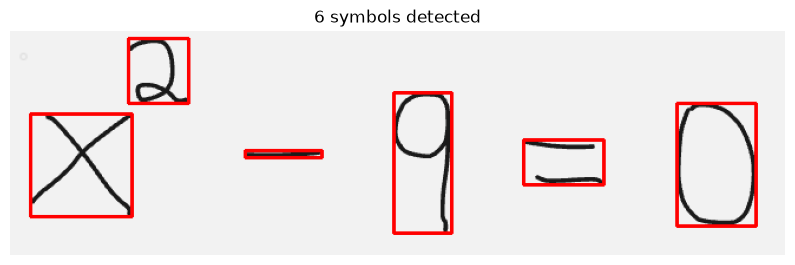

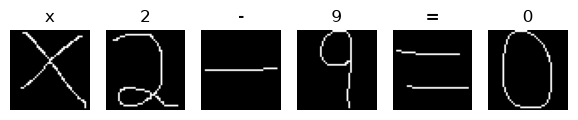

Equation: x^2-9=0
Tokens:   ['x', '^', '2', '-', '9', '=', '0']
LaTeX:    x^2-9=0
Result:   [-3, 3]


In [12]:
# Test Image Input and Equation Recognition
############################################

test_path = os.path.join(EXAMPLES_DIR, 'quadratic.png')

equation, _ = process_equation_image(test_path)
tokens = tokenize(equation)

print("Equation:", equation)
print("Tokens:  ", tokens)
print("LaTeX:   ", clean_latex(tokens_to_latex(tokens)))
print("Result:  ", solve_tokens(tokens)[1])

In [13]:
# Run every image in examples/ (without the step-by-step plots)
############################################

SHOW_STEPS = False
for name in sorted(os.listdir(EXAMPLES_DIR)):
    if not name.lower().endswith(('.png', '.jpg', '.jpeg')):
        continue
    print(f"\n=== {name} ===")
    equation, _ = process_equation_image(os.path.join(EXAMPLES_DIR, name))
    tokens = tokenize(equation)
    try:
        result = solve_tokens(tokens)[1]
    except Exception as e:
        result = f"could not solve ({type(e).__name__})"
    print(f"Equation: {equation}  ->  {result}")
SHOW_STEPS = True


=== addition.png ===
Equation: 1+3  ->  4

=== exponent.png ===
Equation: 4^(3+5)  ->  65536

=== fraction.png ===


Equation: 3div3  ->  1

=== inequality.png ===


Equation: 13gt6  ->  True

=== inequality_geq.png ===
Equation: -6+7geq-9  ->  True

=== integral.png ===
Equation: int(5+2x)dx  ->  x**2 + 5*x

=== integral_power.png ===


Equation: intx^4dx  ->  x**5/5

=== negative_exponent.png ===
Equation: 4^2+3^(-1)  ->  \frac{49}{3}

=== parentheses.png ===


Equation: (7-5)*9  ->  18

=== quadratic.png ===
Equation: x^2-9=0  ->  [-3, 3]

=== subtraction.png ===
Equation: 44-3  ->  41
